# STEP 3. 데이터 불러오기와 품질 점검

- 데이터: Google Trends "해외여행" 검색 관심도 (대한민국, 주간, 2021-11-07 ~ 2026-11-08)
- 값: 0~100 상대 지수 (실제 검색 횟수가 아님)
- 출처 표기: Data source: Google Trends (https://www.google.com/trends)

## 처리 기준 (STEP 3에서 확정)

| 구분 | 기준 | 이유 |
|---|---|---|
| 결측치 | 있으면 채우지 않고 개수와 위치를 기록한다 | 상대 지수라 보간값은 근거가 약하다 |
| 마지막 주 | 통계에서 제외하고 원본 파일에는 유지한다 | 수집일(2026-11-09)에 끝나지 않은 주일 수 있다 |
| 이상치 | 13주 이동 중앙값에서 크게 벗어난 주를 표시만 하고 삭제하지 않는다 | 급증이 실제 관심 변화일 수 있고, 추세가 있어 전체 분포 기준은 부적합하다 |

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

print("Python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)

Python : 3.13.17
numpy  : 2.4.6
pandas : 2.2.3


## 1. 불러오기

원본 CSV는 1행이 카테고리, 2행이 빈 줄, 3행이 열 이름이다. 앞 2줄을 건너뛰고 읽는다.

In [3]:
# 로컬에서는 data 폴더의 파일을, 파일이 없으면(Colab 등) GitHub의 원본 주소를 사용한다
CSV_PATH = Path("data/google_trends_overseas_travel_raw.csv")
RAW_URL = (
    "https://raw.githubusercontent.com/geunwa/"
    "overseas-travel-trend-analysis/main/data/google_trends_overseas_travel_raw.csv"
)
source = CSV_PATH if CSV_PATH.exists() else RAW_URL

raw = pd.read_csv(source, skiprows=2, encoding="utf-8-sig")
raw.columns = ["date", "value"]
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.sort_values("date").reset_index(drop=True)

print("읽은 곳:", source)
print("행, 열 :", raw.shape)
print(raw.head(3))
print(raw.tail(3))

읽은 곳: data\google_trends_overseas_travel_raw.csv
행, 열 : (262, 2)
        date  value
0 2021-11-07     25
1 2021-11-14     22
2 2021-11-21     20
          date  value
259 2026-10-25     82
260 2026-11-01     77
261 2026-11-08     74


## 2. 품질 점검

결측치, 중복 날짜, 주 간격, 요일, 0값, 값의 범위를 확인한다.

In [4]:
gaps = raw["date"].diff().dt.days.dropna()

checks = pd.DataFrame(
    {
        "점검 항목": [
            "행 수",
            "결측치 수",
            "중복 날짜 수",
            "주 간격이 7일이 아닌 곳",
            "일요일이 아닌 날짜",
            "값이 0인 주",
            "값 최솟값",
            "값 최댓값",
        ],
        "결과": [
            len(raw),
            int(raw["value"].isna().sum()),
            int(raw["date"].duplicated().sum()),
            int((gaps != 7).sum()),
            int((raw["date"].dt.dayofweek != 6).sum()),
            int((raw["value"] == 0).sum()),
            int(raw["value"].min()),
            int(raw["value"].max()),
        ],
    }
)
print(checks.to_string(index=False))

         점검 항목  결과
           행 수 262
         결측치 수   0
       중복 날짜 수   0
주 간격이 7일이 아닌 곳   0
    일요일이 아닌 날짜   0
       값이 0인 주   0
         값 최솟값  11
         값 최댓값 100


## 3. 마지막 주 처리

수집일(2026-11-09)에 끝나지 않았을 수 있는 마지막 주(2026-11-08)를 분석용 데이터에서 제외한다. 원본 파일은 바꾸지 않는다.

In [5]:
raw["is_partial"] = raw["date"] == raw["date"].max()
data = raw[~raw["is_partial"]].drop(columns="is_partial").reset_index(drop=True)

print("전체 :", len(raw), "주")
print("분석 :", len(data), "주")
print("제외한 주")
print(raw.loc[raw["is_partial"], ["date", "value"]])

전체 : 262 주
분석 : 261 주
제외한 주
          date  value
261 2026-11-08     74


## 4. 이상치 표시

- 각 주의 값에서 앞뒤 13주(약 한 분기)의 중앙값을 뺀 편차를 구한다.
- 편차가 중앙값 절대 편차(MAD) 기준으로 크게 벗어나면(로버스트 z 점수 절댓값 3.5 초과) 이상치로 표시한다.
- 표시만 하고 삭제하지 않는다.

In [6]:
WINDOW = 13        # 13주 = 약 한 분기
THRESHOLD = 3.5    # 로버스트 z 점수 기준

data["median_13w"] = data["value"].rolling(WINDOW, center=True, min_periods=7).median()
data["deviation"] = data["value"] - data["median_13w"]

center = data["deviation"].median()
mad = (data["deviation"] - center).abs().median()
assert mad > 0, "MAD가 0이면 이상치 기준을 다시 정해야 한다"

data["robust_z"] = 0.6745 * (data["deviation"] - center) / mad
data["is_outlier"] = data["robust_z"].abs() > THRESHOLD

print("MAD :", mad)
print("이상치로 표시된 주:", int(data["is_outlier"].sum()), "개")
print(data.loc[data["is_outlier"], ["date", "value", "median_13w", "robust_z"]].round(2).to_string(index=False))

MAD : 2.0
이상치로 표시된 주: 4 개
      date  value  median_13w  robust_z
2024-12-01     60        49.0      3.71
2026-10-11     73        40.5     10.96
2026-10-18    100        41.0     19.90
2026-10-25     82        57.0      8.43


## 5. 분석용 데이터 저장

원본은 `data/google_trends_overseas_travel_raw.csv`에 그대로 두고, 처리 결과는 별도 파일로 저장한다.

In [7]:
Path("data").mkdir(exist_ok=True)
OUT_PATH = "data/weekly_clean.csv"
data.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")
print("저장:", OUT_PATH, data.shape)

저장: data/weekly_clean.csv (261, 6)


In [8]:
# 이동평균(Moving Average): 최근 N주의 평균을 한 주씩 밀면서 구한다
# 4주 = 약 한 달의 짧은 흐름, 52주 = 1년의 긴 흐름(계절 변동이 평균에 섞여 사라진다)
series = data.set_index("date")["value"]

ma = pd.DataFrame(
    {
        "value": series,
        "ma_4w": series.rolling(4).mean(),
        "ma_52w": series.rolling(52).mean(),
    }
)

print("52주 평균이 처음 계산되는 날:", ma["ma_52w"].first_valid_index().date())
print(ma.tail(8).round(2))

52주 평균이 처음 계산되는 날: 2022-10-30
            value  ma_4w  ma_52w
date                            
2026-09-13     33  34.50   43.92
2026-09-20     40  35.75   43.85
2026-09-27     41  37.50   43.58
2026-10-04     34  37.00   43.31
2026-10-11     73  47.00   43.77
2026-10-18    100  62.00   44.88
2026-10-25     82  72.25   45.62
2026-11-01     77  83.00   46.15


In [9]:
# 달력 연도는 2021년(8주)과 2026년(45주)이 불완전하다
# 그래서 첫 주를 빼고 52주씩 5묶음으로 나눠 비교한다 (1묶음 = 약 1년)
blocks = data.iloc[1:].reset_index(drop=True).copy()
blocks["block"] = blocks.index // 52 + 1

summary = blocks.groupby("block").agg(
    start=("date", "min"),
    end=("date", "max"),
    weeks=("value", "size"),
    mean=("value", "mean"),
    median=("value", "median"),
    max=("value", "max"),
    outliers=("is_outlier", "sum"),
)
summary["growth_pct"] = summary["mean"].pct_change() * 100

# 이상치로 표시된 주를 뺀 평균 (급증이 결과를 얼마나 바꾸는지 확인용)
summary["mean_no_outlier"] = blocks[~blocks["is_outlier"]].groupby("block")["value"].mean()
summary["growth_no_outlier_pct"] = summary["mean_no_outlier"].pct_change() * 100

num_cols = ["mean", "median", "growth_pct", "mean_no_outlier", "growth_no_outlier_pct"]
summary[num_cols] = summary[num_cols].round(2)
print(summary.to_string())

total_change = (summary["mean"].iloc[-1] / summary["mean"].iloc[0] - 1) * 100
print("\n첫 묶음 대비 마지막 묶음 변화율:", round(total_change, 1), "%")

           start        end  weeks   mean  median  max  outliers  growth_pct  mean_no_outlier  growth_no_outlier_pct
block                                                                                                               
1     2021-11-14 2022-11-06     52  27.62    32.0   39         0         NaN            27.62                    NaN
2     2022-11-13 2023-11-05     52  39.83    39.0   55         0       44.22            39.83                  44.22
3     2023-11-12 2024-11-03     52  38.81    39.0   49         0       -2.56            38.81                  -2.56
4     2024-11-10 2025-11-02     52  46.23    46.5   60         1       19.13            45.96                  18.43
5     2025-11-09 2026-11-01     52  46.15    41.0  100         3       -0.17            43.78                  -4.75

첫 묶음 대비 마지막 묶음 변화율: 67.1 %


In [10]:
ma52 = ma["ma_52w"].dropna()
peak_date = ma52.idxmax()
before_spike = ma52.loc["2026-09-27"]

print("52주 평균 처음  :", round(ma52.iloc[0], 2), ma52.index[0].date())
print("52주 평균 최고  :", round(ma52.max(), 2), peak_date.date())
print("52주 평균 9/27  :", round(before_spike, 2))
print("52주 평균 마지막:", round(ma52.iloc[-1], 2), ma52.index[-1].date())
print("최고점 대비 9/27 변화율:", round((before_spike / ma52.max() - 1) * 100, 1), "%")

52주 평균 처음  : 27.35 2022-10-30
52주 평균 최고  : 47.35 2026-04-05
52주 평균 9/27  : 43.58
52주 평균 마지막: 46.15 2026-11-01
최고점 대비 9/27 변화율: -8.0 %


In [11]:
# 전주 대비 변화: 이번 주 값에서 지난주 값을 뺀 값(diff)과 변화율(pct_change)
change = pd.DataFrame(
    {
        "value": series,
        "diff": series.diff(),
        "pct": series.pct_change() * 100,
    }
)
print(change.tail(8).round(2))

# 평소 변동의 크기: 주간 변화율의 평균과 표준편차 (260주)
pct = change["pct"].dropna()
print("\n주간 변화율 평균:", round(pct.mean(), 2), "%  표준편차:", round(pct.std(), 2), "%")

# 변화폭(절대값)이 큰 주 5개
top = change["diff"].abs().sort_values(ascending=False).head(5).index
print("\n변화폭 상위 5주")
print(change.loc[top, ["value", "diff", "pct"]].round(2))

            value  diff     pct
date                           
2026-09-13     33  -3.0   -8.33
2026-09-20     40   7.0   21.21
2026-09-27     41   1.0    2.50
2026-10-04     34  -7.0  -17.07
2026-10-11     73  39.0  114.71
2026-10-18    100  27.0   36.99
2026-10-25     82 -18.0  -18.00
2026-11-01     77  -5.0   -6.10

주간 변화율 평균: 1.2 %  표준편차: 13.32 %

변화폭 상위 5주
            value  diff     pct
date                           
2026-10-11     73  39.0  114.71
2026-10-18    100  27.0   36.99
2026-10-25     82 -18.0  -18.00
2026-02-08     44 -13.0  -22.81
2024-12-01     60  12.0   25.00


In [12]:
# 급증 전 13주(기준선)와 급증 후 4주를 비교한다
baseline = series["2026-07-12":"2026-10-04"]
after = series["2026-10-11":]
base_mean = baseline.mean()

print("기준선 13주 평균:", round(base_mean, 2), " 중앙값:", baseline.median())
print("급증 후 4주 평균:", round(after.mean(), 2))
print("기준선 대비 배수:", round(after.mean() / base_mean, 2), "배")

# 정점(10-18) 이후 얼마나 남아 있는가: 잔존율 = (값 - 기준선) / (정점 - 기준선)
peak = series.loc["2026-10-18"]
post = series["2026-10-18":]
last_week = raw[raw["is_partial"]].set_index("date")["value"]  # 통계에서 뺀 마지막 주
post = pd.concat([post, last_week])

result = pd.DataFrame(
    {
        "value": post,
        "excess": (post - base_mean).round(2),
        "retention": ((post - base_mean) / (peak - base_mean)).round(3),
    }
)
result["note"] = ["정점", "", "", "미완성 가능, 통계 제외"]
print()
print(result)

기준선 13주 평균: 36.15  중앙값: 35.0
급증 후 4주 평균: 83.0
기준선 대비 배수: 2.3 배

            value  excess  retention           note
date                                               
2026-10-18    100   63.85      1.000             정점
2026-10-25     82   45.85      0.718               
2026-11-01     77   40.85      0.640               
2026-11-08     74   37.85      0.593  미완성 가능, 통계 제외


In [13]:
# 비교 사례: 2024-12-01 이상치(60) 전후
spike = pd.Timestamp("2024-12-01")
before4 = series[spike - pd.Timedelta(weeks=4) : spike - pd.Timedelta(weeks=1)]
after8 = series[spike + pd.Timedelta(weeks=1) : spike + pd.Timedelta(weeks=8)]

print("급증 전 4주 평균:", round(before4.mean(), 2))
print("급증 값        :", series.loc[spike])
print("급증 후 8주 평균:", round(after8.mean(), 2))
retention_2024 = (after8.mean() - before4.mean()) / (series.loc[spike] - before4.mean())
print("후 8주 평균의 잔존율:", round(retention_2024, 3))

급증 전 4주 평균: 42.25
급증 값        : 60
급증 후 8주 평균: 53.25
후 8주 평균의 잔존율: 0.62


In [14]:
# 월별 집계: 각 주를 '주 시작일이 속한 달'에 넣고 달별 평균을 구한다
tmp = data.copy()
tmp["month"] = tmp["date"].dt.to_period("M").dt.to_timestamp()
by_month = tmp.groupby("month")["value"].agg(mean="mean", weeks="count")

print("달별 주 수 분포:", by_month["weeks"].value_counts().sort_index().to_dict())

# 주가 4개 미만인 달은 평균이 불안정하므로 뺀다
short = by_month[by_month["weeks"] < 4]
print("제외한 달:", [d.strftime("%Y-%m") for d in short.index])

monthly = by_month[by_month["weeks"] >= 4]["mean"]
print("월별 점 개수:", len(monthly), "|", monthly.index[0].strftime("%Y-%m"), "~", monthly.index[-1].strftime("%Y-%m"))
print(monthly.round(2).head(3))
print(monthly.round(2).tail(3))

달별 주 수 분포: {1: 1, 4: 40, 5: 20}
제외한 달: ['2026-11']
월별 점 개수: 60 | 2021-11 ~ 2026-10
month
2021-11-01    20.25
2021-12-01    14.75
2022-01-01    16.40
Name: mean, dtype: float64
month
2026-08-01    35.20
2026-09-01    37.50
2026-10-01    72.25
Name: mean, dtype: float64


In [15]:
import numpy as np

# 고전적 가법 분해: 값 = 추세 + 계절 + 잡음
# 추세: 12개월 이동평균을 한 번 더 평균낸 2x12 중심 이동평균 (양 끝 6개월은 계산 불가)
weights = np.r_[0.5, np.ones(11), 0.5] / 12
trend = monthly.rolling(13, center=True).apply(lambda a: (a * weights).sum(), raw=True)

# 계절: 추세를 뺀 값을 같은 달끼리 평균하고, 전체 평균이 0이 되도록 맞춘다
detrended = monthly - trend
seasonal_by_month = detrended.groupby(detrended.index.month).mean()
seasonal_by_month = seasonal_by_month - seasonal_by_month.mean()
seasonal = pd.Series(seasonal_by_month.reindex(monthly.index.month).values, index=monthly.index)

# 잡음: 추세와 계절로 설명되지 않고 남은 값
noise = monthly - trend - seasonal

valid = noise.notna()
print("추세 계산된 달:", int(valid.sum()), "|", trend.dropna().index[0].strftime("%Y-%m"), "~", trend.dropna().index[-1].strftime("%Y-%m"))
print()
print(seasonal_by_month.round(2).rename("seasonal").to_frame())

# 계절성 강도: 1에 가까울수록 계절 패턴이 뚜렷하다
strength = 1 - noise[valid].var() / (noise[valid] + seasonal[valid]).var()
print("\n계절성 강도:", round(strength, 3))
print("잡음 표준편차:", round(noise[valid].std(), 2))

추세 계산된 달: 48 | 2022-05 ~ 2026-04

       seasonal
month          
1         10.25
2          0.93
3         -3.76
4         -6.19
5         -1.81
6          0.41
7          1.36
8         -0.80
9         -2.49
10        -4.77
11         0.43
12         6.44

계절성 강도: 0.734
잡음 표준편차: 2.69


In [16]:
# 연도별 최고·최저 달: 계절 패턴이 해마다 반복되는지 확인한다
yearly = monthly.to_frame("mean")
yearly["year"] = yearly.index.year
check = yearly.groupby("year")["mean"].agg(
    months="count",
    peak_month=lambda s: s.idxmax().month,
    peak=lambda s: round(s.max(), 2),
    low_month=lambda s: s.idxmin().month,
    low=lambda s: round(s.min(), 2),
)
print(check)

# 계절 지수가 가장 낮은 2개와 가장 높은 2개
ranked = seasonal_by_month.sort_values()
print("\n낮은 달:", ranked.head(2).round(2).to_dict())
print("높은 달:", ranked.tail(2).round(2).to_dict())

      months  peak_month   peak  low_month    low
year                                             
2021       2          11  20.25         12  14.75
2022      12          12  45.25          1  16.40
2023      12           1  53.40         10  32.80
2024      12          12  53.40          4  34.00
2025      12           1  54.75          4  37.75
2026      10          10  72.25          4  34.25

낮은 달: {4: -6.19, 10: -4.77}
높은 달: {12: 6.44, 1: 10.25}


In [17]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 한글 폰트: 설치된 것 중 첫 번째를 쓴다 (Windows는 Malgun Gothic)
candidates = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]
installed = {f.name for f in font_manager.fontManager.ttflist}
font = next((name for name in candidates if name in installed), None)
if font:
    plt.rcParams["font.family"] = font
else:
    print("경고: 한글 폰트를 찾지 못했다. 글자가 네모로 보일 수 있다.")
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 기호 깨짐 방지

Path("images").mkdir(exist_ok=True)
SOURCE = "데이터 출처: Google Trends (https://www.google.com/trends)"
print("사용 폰트:", font)

사용 폰트: Malgun Gothic


저장: images/fig1_weekly_trend.png


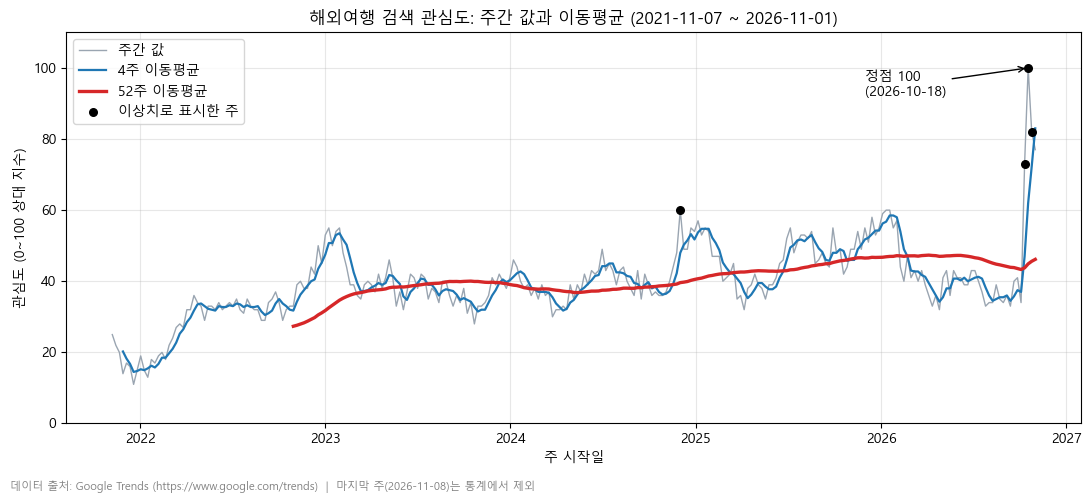

In [18]:
# 그림 1: 주간 값과 이동평균 (Q1 추세, Q3 급증)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ma.index, ma["value"], color="#9aa5b1", linewidth=1, label="주간 값")
ax.plot(ma.index, ma["ma_4w"], color="#1f77b4", linewidth=1.6, label="4주 이동평균")
ax.plot(ma.index, ma["ma_52w"], color="#d62728", linewidth=2.4, label="52주 이동평균")

flagged = data[data["is_outlier"]]
ax.scatter(flagged["date"], flagged["value"], color="black", s=30, zorder=5, label="이상치로 표시한 주")
ax.annotate("정점 100\n(2026-10-18)", xy=(pd.Timestamp("2026-10-18"), 100),
            xytext=(pd.Timestamp("2025-12-01"), 92), arrowprops={"arrowstyle": "->"})

ax.set_title("해외여행 검색 관심도: 주간 값과 이동평균 (2021-11-07 ~ 2026-11-01)")
ax.set_xlabel("주 시작일")
ax.set_ylabel("관심도 (0~100 상대 지수)")
ax.set_ylim(0, 110)
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
fig.text(0.01, 0.01, SOURCE + "  |  마지막 주(2026-11-08)는 통계에서 제외", fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("images/fig1_weekly_trend.png", dpi=150)
print("저장: images/fig1_weekly_trend.png")
plt.show()

저장: images/fig2_monthly_seasonality.png


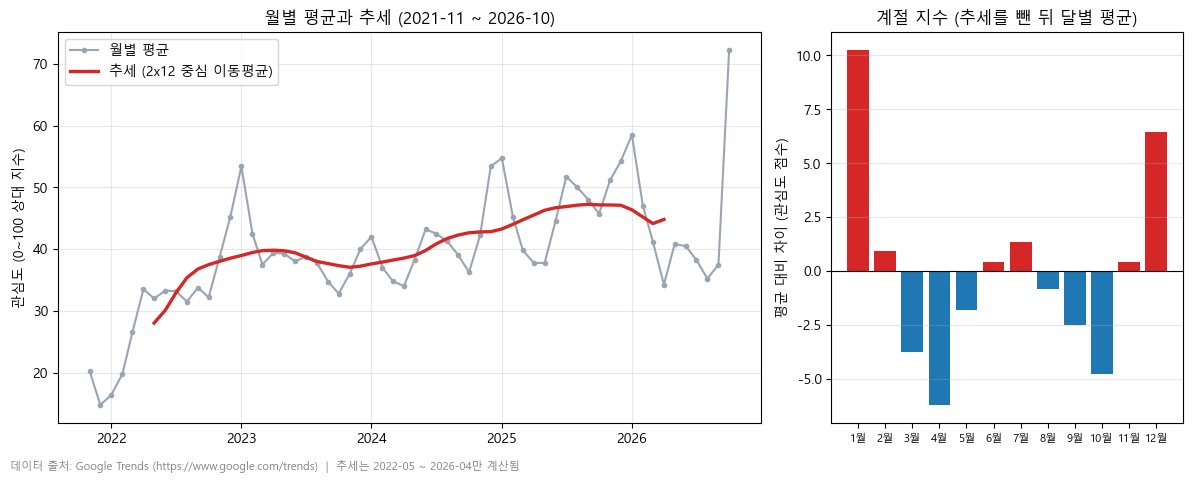

In [19]:
# 그림 2: 월별 평균과 추세, 계절 지수 (Q2 계절성)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [2, 1]})

ax1.plot(monthly.index, monthly.values, marker="o", markersize=3, color="#9aa5b1", label="월별 평균")
ax1.plot(trend.index, trend.values, color="#d62728", linewidth=2.4, label="추세 (2x12 중심 이동평균)")
ax1.set_title("월별 평균과 추세 (2021-11 ~ 2026-10)")
ax1.set_ylabel("관심도 (0~100 상대 지수)")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left")

months = list(range(1, 13))
values = seasonal_by_month.reindex(months).values
colors = ["#d62728" if v > 0 else "#1f77b4" for v in values]
ax2.bar(months, values, color=colors)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(months)
ax2.set_xticklabels([f"{m}월" for m in months], fontsize=8)
ax2.set_title("계절 지수 (추세를 뺀 뒤 달별 평균)")
ax2.set_ylabel("평균 대비 차이 (관심도 점수)")
ax2.grid(axis="y", alpha=0.3)

fig.text(0.01, 0.01, SOURCE + "  |  추세는 2022-05 ~ 2026-04만 계산됨", fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("images/fig2_monthly_seasonality.png", dpi=150)
print("저장: images/fig2_monthly_seasonality.png")
plt.show()

저장: images/fig3_spike_zoom.png


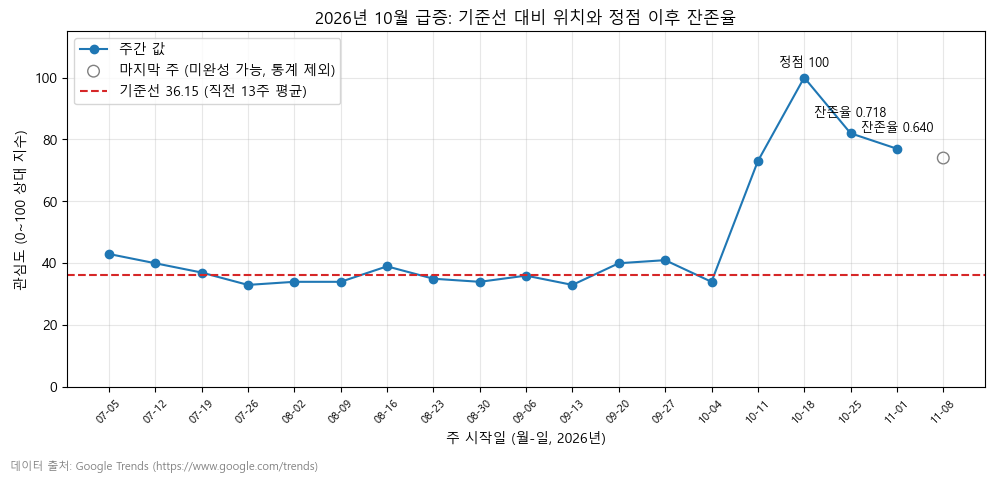

In [20]:
# 그림 3: 2026년 10월 급증 확대 (Q3)
zoom = series["2026-07-05":]
partial = raw[raw["is_partial"]].set_index("date")["value"]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(zoom.index, zoom.values, marker="o", color="#1f77b4", label="주간 값")
ax.scatter(partial.index, partial.values, facecolors="none", edgecolors="gray", s=70,
           label="마지막 주 (미완성 가능, 통계 제외)")
ax.axhline(base_mean, color="#d62728", linestyle="--", label=f"기준선 {base_mean:.2f} (직전 13주 평균)")

for date_text in ["2026-10-25", "2026-11-01"]:
    day = pd.Timestamp(date_text)
    retention_value = (series.loc[day] - base_mean) / (peak - base_mean)
    ax.annotate(f"잔존율 {retention_value:.3f}", xy=(day, series.loc[day]),
                xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9)
ax.annotate("정점 100", xy=(pd.Timestamp("2026-10-18"), 100), xytext=(0, 8),
            textcoords="offset points", ha="center", fontsize=9)

ax.set_title("2026년 10월 급증: 기준선 대비 위치와 정점 이후 잔존율")
ax.set_xlabel("주 시작일 (월-일, 2026년)")
ax.set_ylabel("관심도 (0~100 상대 지수)")
ax.set_ylim(0, 115)
week_starts = list(zoom.index) + list(partial.index)
ax.set_xticks(week_starts)
ax.set_xticklabels([d.strftime("%m-%d") for d in week_starts], rotation=45, fontsize=8)
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
fig.text(0.01, 0.01, SOURCE, fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("images/fig3_spike_zoom.png", dpi=150)
print("저장: images/fig3_spike_zoom.png")
plt.show()

In [21]:
def detect(series, window, thr):
    med = series.rolling(window, center=True, min_periods=(window + 1) // 2).median()
    dev = series - med
    mad = (dev - dev.median()).abs().median()
    z = 0.6745 * (dev - dev.median()) / mad
    return z[z > thr].index

windows = [9, 13, 17, 26]
thresholds = [3.0, 3.5, 4.0]

count = pd.DataFrame(index=windows, columns=thresholds, dtype=int)
for w in windows:
    for t in thresholds:
        count.loc[w, t] = len(detect(series, w, t))
count.index.name = "창(주)"
print(count)

key_weeks = pd.to_datetime(["2024-12-01", "2026-10-11", "2026-10-18", "2026-10-25"])
rows = []
for w in windows:
    for t in thresholds:
        found = detect(series, w, t)
        rows.append([w, t] + [bool(d in found) for d in key_weeks])
key = pd.DataFrame(rows, columns=["창", "임계값"] + [d.strftime("%Y-%m-%d") for d in key_weeks])
print(key.to_string(index=False))
print(key.iloc[:, 2:].sum())

       3.0  3.5  4.0
창(주)                
9      4.0  3.0  2.0
13     4.0  4.0  3.0
17    10.0  7.0  4.0
26     9.0  4.0  4.0
 창  임계값  2024-12-01  2026-10-11  2026-10-18  2026-10-25
 9  3.0        True        True        True       False
 9  3.5        True        True        True       False
 9  4.0       False        True        True       False
13  3.0        True        True        True        True
13  3.5        True        True        True        True
13  4.0       False        True        True        True
17  3.0        True        True        True        True
17  3.5        True        True        True        True
17  4.0       False        True        True        True
26  3.0        True        True        True        True
26  3.5       False        True        True        True
26  4.0       False        True        True        True
2024-12-01     7
2026-10-11    12
2026-10-18    12
2026-10-25     9
dtype: int64


In [22]:
from pathlib import Path

EXT = Path("data/external/korea_tourism_annual_stats_1975_2025.xlsx")
ext = pd.read_excel(EXT, sheet_name="국민 해외관광객", header=None, skiprows=6)
ext = ext.iloc[:, :15]
ext.columns = ["year", "total", "growth"] + list(range(1, 13))
ext = ext[pd.to_numeric(ext["year"], errors="coerce").notna()].copy()
ext["year"] = ext["year"].astype(int)
ext = ext[ext["year"].between(2021, 2025)].set_index("year")
months = list(range(1, 13))

print(ext["total"])
print("월 합계 - 연 합계 최대 차이:", (ext[months].sum(axis=1) - ext["total"]).abs().max())

ratio = ext.loc[[2024, 2025], months].div(ext.loc[[2024, 2025], "total"] / 12, axis=0).mean()
ours = pd.Series(seasonal_by_month).sort_index().to_numpy()
assert len(ours) == 12
print("우리 계절 지수:", ours.round(2))
print("실제 출국자 비율:", ratio.round(3).to_numpy())
ours_s, ratio_s = pd.Series(ours), pd.Series(ratio.to_numpy())
print("Pearson:", round(ours_s.corr(ratio_s), 3), "Spearman:", round(ours_s.rank().corr(ratio_s.rank()), 3))

mon = ext[months].stack()
mon.index = pd.to_datetime([f"{y}-{m:02d}-01" for y, m in mon.index])
blk = mon.groupby((mon.index + pd.DateOffset(months=2)).year).sum().loc[2022:2025]
print(blk)
print((blk.pct_change() * 100).round(1))

year
2021     1222541.0
2022     6554031.0
2023    22715841.0
2024    28686435.0
2025    29550177.0
Name: total, dtype: float64
월 합계 - 연 합계 최대 차이: 0.0
우리 계절 지수: [10.25  0.93 -3.76 -6.19 -1.81  0.41  1.36 -0.8  -2.49 -4.77  0.43  6.44]
실제 출국자 비율: [1.183 1.059 0.894 0.878 0.96  0.916 1.018 0.985 0.938 1.042 1.001 1.126]
Pearson: 0.836 Spearman: 0.748
2022     4406590.0
2023    20673202.0
2024    28056570.0
2025    29442661.0
dtype: float64
2022      NaN
2023    369.1
2024     35.7
2025      4.9
dtype: float64


In [23]:
months_9_10 = pd.DataFrame({
    "9월": monthly[monthly.index.month == 9].to_numpy(),
    "10월": monthly[monthly.index.month == 10].to_numpy(),
}, index=monthly[monthly.index.month == 10].index.year)
months_9_10["10월 - 9월"] = months_9_10["10월"] - months_9_10["9월"]
print(months_9_10.round(2))

          9월    10월  10월 - 9월
month                        
2022   33.75  32.20     -1.55
2023   34.75  32.80     -1.95
2024   39.00  36.25     -2.75
2025   48.00  45.75     -2.25
2026   37.50  72.25     34.75


In [24]:
train = series[:"2026-07-05"]
test = series["2026-07-12":"2026-10-04"]

forecasts = pd.DataFrame({
    "실제": test,
    "직전값": train.iloc[-1],
    "13주 평균": train.iloc[-13:].mean(),
    "작년 같은 주": series.shift(52)[test.index],
})
print(forecasts.round(2))

mae = {name: (forecasts["실제"] - forecasts[name]).abs().mean()
       for name in ["직전값", "13주 평균", "작년 같은 주"]}
print("평균 절대 오차(MAE):", {k: round(v, 2) for k, v in mae.items()})

best = min(mae, key=mae.get)
level = series["2026-07-12":"2026-10-04"].mean()
spike = series["2026-10-11":"2026-11-01"]
print("가장 정확한 방법:", best, "/ 급증 직전 13주 평균:", round(level, 2))
print((spike - level).round(2).rename("기준선 대비 차이"))

            실제  직전값  13주 평균  작년 같은 주
date                                
2026-07-12  40   43   39.23     48.0
2026-07-19  37   43   39.23     51.0
2026-07-26  33   43   39.23     53.0
2026-08-02  34   43   39.23     53.0
2026-08-09  34   43   39.23     52.0
2026-08-16  39   43   39.23     54.0
2026-08-23  35   43   39.23     45.0
2026-08-30  34   43   39.23     46.0
2026-09-06  36   43   39.23     48.0
2026-09-13  33   43   39.23     45.0
2026-09-20  40   43   39.23     44.0
2026-09-27  41   43   39.23     55.0
2026-10-04  34   43   39.23     48.0
평균 절대 오차(MAE): {'직전값': np.float64(6.85), '13주 평균': np.float64(3.59), '작년 같은 주': np.float64(13.23)}
가장 정확한 방법: 13주 평균 / 급증 직전 13주 평균: 36.15
date
2026-10-11    36.85
2026-10-18    63.85
2026-10-25    45.85
2026-11-01    40.85
Name: 기준선 대비 차이, dtype: float64
